![Banner](../images/09_11_banner_rs_foundation_models.png)

# Time in Foundation Models: Prithvi-TL, AnySat, Presto and Galileo

A crop is defined less by how it looks on one day than by how it changes through a season: when it
emerges, how fast it greens up, when it senesces. Classical crop mapping therefore stacks many dates.
This notebook asks how foundation models handle time. It feeds one to four Sentinel-2 dates of the
2025 Iowa season to Prithvi-EO-2.0 with and without date and location inputs, runs AnySat on the
same series, compares both with NDVI phenology features, and measures how early in the season corn
and soybeans can be told apart. Presto and Galileo, pixel time series models that run through their
authors' code, are introduced at the end.

## Overview

### Pixel time series and image time series

A **pixel time series** is the sequence of values of one pixel through the season, the input of
phenology methods and of Presto. An **image time series** is a stack of images; models that read it
can also use the spatial pattern of each date. Real series are irregular: clouds remove dates, and
satellites revisit at different intervals.

### How models take time

| Mechanism | How it works | Models |
|---|---|---|
| 3-D patches | a token covers several dates of a 16 x 16 pixel patch | Prithvi-EO (tubelets) |
| date tokens | the acquisition date (year, day of year) is encoded and added to the tokens | Prithvi-EO-2.0-TL, AnySat, Galileo |
| location tokens | latitude and longitude are encoded, so the model can learn regional crop calendars | Prithvi-EO-2.0-TL, Presto |
| temporal attention | tokens of different dates attend to each other, then are pooled over time | AnySat, Galileo, L-TAE heads |
| per-pixel sequence models | a small transformer reads each pixel's monthly values from many sensors | Presto |

Prithvi-EO-2.0-300M-TL is the same network as Prithvi-EO-2.0-300M plus temporal and location
encodings. In TerraTorch both take `num_frames`; only the TL variant uses `temporal_coords` and
`location_coords`, which `embed_raster(metadata=True)` fills from the raster's dates and coordinates
(`fm.chip_metadata`).

### Early-season mapping

Crop maps are most valuable before harvest, for yield forecasts, insurance and markets. The question
is not only "how accurate with the whole season?" but "how accurate with the dates available by
June, by July?". Each additional date adds information; a good model uses the early dates well.

### Baselines that are hard to beat

NDVI through the season captures green-up timing, the main difference between corn (planted earlier,
closes canopy earlier) and soybeans. A random forest on a few NDVI dates is a strong baseline, and
any foundation model has to be compared with it.

## Time Series Models with GeoLattice

| Task | GeoLattice |
|---|---|
| chips of a `(time, band, y, x)` series | `fm.chip_raster(series)` -> `(n, band, time, h, w)` |
| Prithvi with several dates | `fm.load_model("prithvi-eo-2.0-300m-tl", num_frames=T)`, `embed_raster(series)` |
| date and location inputs | `embed_raster(series, metadata=True)`, `fm.chip_metadata` |
| AnySat on a series | `fm.load_model("anysat")`, `enc.encode({"s2": ..., "s2_dates": ...})` |
| baselines | NDVI per date, `sklearn` random forest, `fm.linear_probe` |

### Learning objectives

1. Build a four-date Sentinel-2 series and cut it into chips with dates.
2. Embed it with Prithvi-EO-2.0 using one to four frames, with and without date and location inputs.
3. Embed the same series with AnySat, whose dates are explicit inputs.
4. Compare foundation model embeddings with NDVI phenology features under spatial cross-validation.
5. Measure accuracy as the season progresses (early-season mapping).
6. Know when to reach for pixel time series models such as Presto and Galileo.

### Data

| Dataset | Content |
|---|---|
| Corn Belt Sentinel-2 cube | 10 bands at 20 m; 8 May, 22 June, 14 July and 26 August 2025 |
| Cropland Data Layer 2025 | corn and soybean labels on the same grid |

### Contents

- Setup
- A four-date season
- Phenology from NDVI
- Prithvi with one to four frames
- Do dates and location help?
- AnySat on the same series
- How early can crops be mapped?
- Presto and Galileo
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `geolattice[rsense-foundation]`, which no GeoLattice option installs: `pip install "geolattice[rsense-foundation]"`.

In [1]:
import os  # environment variables
os.environ.setdefault("USE_TF", "0")  # keep transformers from loading TensorFlow
import time  # timing
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import torch  # PyTorch: every model runs on it
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.foundation_models as fm  # catalog, loaders, embeddings and probes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing")  # remote sensing data folder
IC = DATA / "09_09_image_classification"  # data shared with the image classification chapter
CAP = DATA / "08_11_Capstones"  # data shared with the capstones
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # run models on the GPU when there is one
SEED = 0  # one seed for every random step
np.random.seed(SEED)  # NumPy
torch.manual_seed(SEED)  # PyTorch

print("GeoLattice", geolattice.__version__, "| PyTorch", torch.__version__, "| device", DEVICE)  # versions used
if DEVICE == "cuda":  # name the GPU
    print("GPU:", torch.cuda.get_device_name(0))  # GPU model

CUBE = IC / "Corn_belt" / "cache_20m"  # Corn Belt cubes on the 20 m grid
DATES = ["2025-05-08", "2025-06-22", "2025-07-14", "2025-08-26"]  # one clear date per month
CELL = 32  # comparison cell in 20 m pixels (640 m)

GeoLattice 0.3.47 | PyTorch 2.14.0+cu132 | device cuda
GPU: NVIDIA RTX A5500 Laptop GPU


## A four-date season

One clear date per month from May to August 2025 is taken from the cube as a `(time, band, y, x)`
DataArray. Corn and soybean cells (640 m, at least 60 % one crop) carry the labels, and 5.8 km
blocks define the spatial folds, as in notebooks 09_11_03 to 09_11_05.

{'time': 4, 'band': 10, 'y': 1456, 'x': 1516} | 1449 cells: {'corn': 940, 'soybeans': 509}


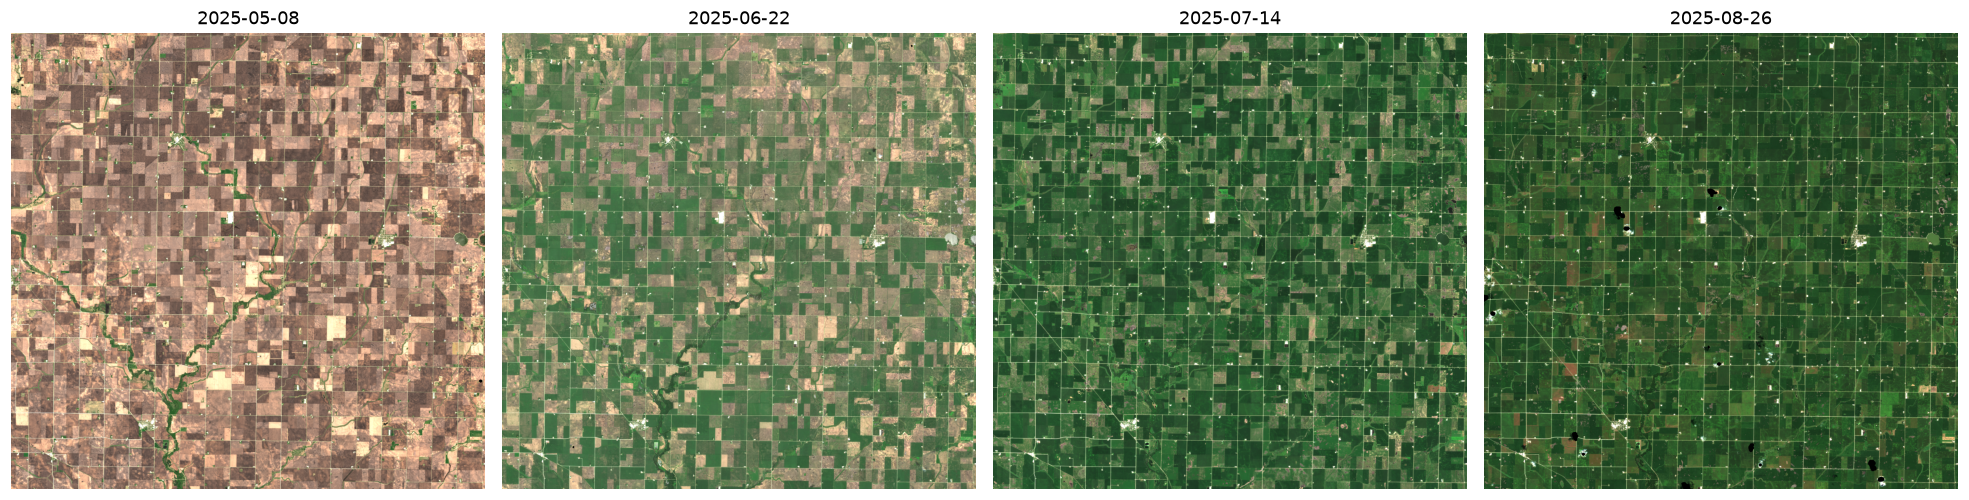

In [2]:
series = xr.open_dataarray(CUBE / "s2_20m.nc").sel(time=DATES).load().rio.write_crs("EPSG:32615")  # (4, 10, y, x)
cdl = xr.open_dataset(CUBE / "labels_20m.nc")["cdl"].sel(year=2025).load()  # CDL 2025
NY, NX = -(-cdl.shape[0] // CELL), -(-cdl.shape[1] // CELL)  # cell grid
pad = np.full((NY * CELL, NX * CELL), -1, cdl.dtype); pad[:cdl.shape[0], :cdl.shape[1]] = cdl.values  # padded CDL
blk = pad.reshape(NY, CELL, NX, CELL).transpose(0, 2, 1, 3).reshape(NY * NX, -1)  # pixels per cell
counts = np.stack([(blk == k).sum(1) for k in (0, 1)], 1)  # corn and soybean pixels
y, purity = counts.argmax(1), counts.max(1) / blk.shape[1]  # label and share
gy, gx = np.divmod(np.arange(NY * NX), NX)  # cell row and column
group = (gy // 9) * 10 + gx // 9  # spatial blocks
ok = purity >= 0.6  # pure corn or soybean cells
print(dict(series.sizes), "|", ok.sum(), "cells:", {"corn": int((y[ok] == 0).sum()), "soybeans": int((y[ok] == 1).sum())})  # summary

fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))  # one panel per date
for a, t in zip(ax, series.time.values):  # every date
    v = series.sel(time=t, band=["red", "green", "blue"]).transpose("y", "x", "band").values  # true colour
    a.imshow(np.clip(np.nan_to_num(v) / 0.15, 0, 1)); a.set_title(str(t)[:10]); a.axis("off")  # one date
plt.tight_layout(); plt.show()  # draw

## Phenology from NDVI

NDVI per date, averaged over each cell, shows the crop calendar: corn greens up earlier than
soybeans, and by August both are at full canopy.

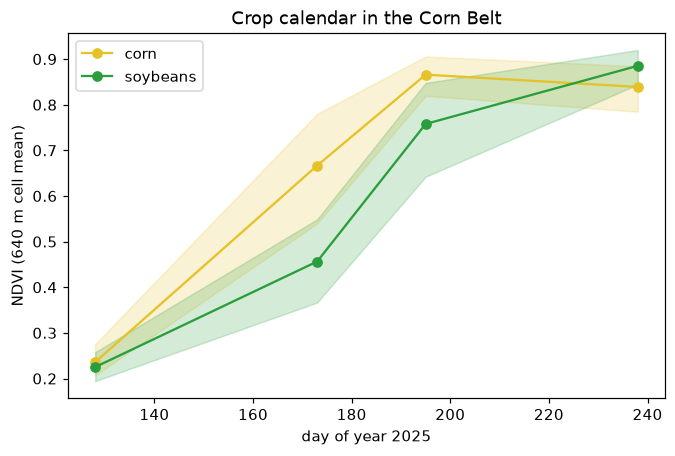

In [3]:
ndvi = ((series.sel(band="nir08") - series.sel(band="red")) / (series.sel(band="nir08") + series.sel(band="red")))  # NDVI per date
nd_cell = ndvi.coarsen(y=CELL, x=CELL, boundary="pad").mean().values[:, :NY, :NX].reshape(len(DATES), -1).T  # (cells, dates)
nd_cell = np.nan_to_num(nd_cell)  # fill rare gaps
fig, ax = plt.subplots(figsize=(7, 4.3))  # one panel
doy = pd.to_datetime(DATES).dayofyear  # day of year
for k, (name, col) in enumerate([("corn", "#e6c229"), ("soybeans", "#2a9d3c")]):  # two crops
    v = nd_cell[ok & (y == k)]  # NDVI series of that crop
    ax.plot(doy, v.mean(0), "o-", color=col, label=name)  # mean
    ax.fill_between(doy, *np.percentile(v, [10, 90], 0), color=col, alpha=0.2)  # 10 to 90 % range
ax.set_xlabel("day of year 2025"); ax.set_ylabel("NDVI (640 m cell mean)"); ax.legend()  # labels
ax.set_title("Crop calendar in the Corn Belt"); plt.show()  # draw

The two crops overlap in May (bare soil), separate in June and July as corn closes its canopy first,
and converge again in August. A model using all four dates can use that difference in timing.

## Prithvi with one to four frames

Prithvi-EO-2.0 reads a series as frames of 3-D patches. Here it reads the last T dates up to August
(T = 1 is the August date alone, T = 4 is May to August), at native resolution in 224 pixel chips,
with patch features averaged over time and to the 640 m grid.

In [4]:
def cells(d):  # (D, y, x) patch map -> (cells, D) on the 640 m grid
    f = int(round(d.sizes["y"] / NY))  # patches per cell side (2 for 320 m patches, 1 for 640 m cells)
    d = d.coarsen(y=f, x=f, boundary="pad").mean() if f > 1 else d  # average 320 m patches into 640 m cells
    return d.values[:, :NY, :NX].reshape(d.sizes["embedding"], -1).T  # (cells, D)


prith, secs = {}, {}  # embeddings and run times
for T in [1, 2, 3, 4]:  # number of frames
    sub = series.isel(time=slice(4 - T, 4))  # the last T dates
    for name in ["prithvi-eo-2.0-300m", "prithvi-eo-2.0-300m-tl"]:  # without and with date/location encodings
        enc = fm.load_model(name, device=DEVICE, num_frames=T)  # Prithvi for T frames
        t0 = time.perf_counter()  # start the clock
        prith[(name, T)] = cells(enc.embed_raster(sub, dense=True, norm="model", batch_size=4,
                                                  metadata=name.endswith("-tl")))  # TL also gets dates and coordinates
        secs[(name, T)] = time.perf_counter() - t0  # seconds
        del enc; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
pd.Series(secs).unstack(0).round(1).rename_axis("frames")  # seconds for the scene

,prithvi-eo-2.0-300m,prithvi-eo-2.0-300m-tl
frames,,
1,1.0,0.9
2,1.6,1.6
3,2.4,2.4
4,3.3,3.4


`fm.chip_metadata` shows what the TL model received for every chip: its centre in degrees and the
year and day of year of every frame.

In [5]:
_, cy, cx = fm.chip_raster(series, chip_size=224)  # chip centres
fm.chip_metadata(cy, cx, series.rio.crs, time=DATES[0], chip_size=224, resolution=20).head(3).round(3)  # first chips

,lon,lat,days,year,doy,area_km2
0,-94.060,43.033,20216.0,2025.0,128.0,20.07
1,-94.005,43.033,20216.0,2025.0,128.0,20.07
2,-93.950,43.034,20216.0,2025.0,128.0,20.07


## Do dates and location help?

Spatial linear probes on every embedding, next to NDVI baselines with the same dates: NDVI values
alone with a linear model, and a random forest on NDVI and the ten band means of each date.

In [6]:
from sklearn.ensemble import RandomForestClassifier  # baseline
from sklearn.model_selection import GroupKFold, cross_val_score  # spatial folds

bm = np.nan_to_num(series.coarsen(y=CELL, x=CELL, boundary="pad").mean().values[..., :NY, :NX]
                   .reshape(len(DATES), 10, -1).transpose(2, 0, 1))  # (cells, dates, bands) band means
rows = []  # results
for T in [1, 2, 3, 4]:  # frames
    sl = slice(4 - T, 4)  # the last T dates
    rf = RandomForestClassifier(300, n_jobs=-1, random_state=SEED)  # random forest
    feats = np.c_[nd_cell[:, sl], bm[:, sl].reshape(len(bm), -1)]  # NDVI + band means of those dates
    rows.append({"frames": T, "input": "NDVI (linear)", "F1": fm.linear_probe(nd_cell[ok, sl], y[ok], groups=group[ok])["mean"]["f1_macro"]})  # NDVI only
    rows.append({"frames": T, "input": "NDVI + bands (random forest)",
                 "F1": cross_val_score(rf, feats[ok], y[ok], groups=group[ok], cv=GroupKFold(5), scoring="f1_macro").mean()})  # RF
    for name in ["prithvi-eo-2.0-300m", "prithvi-eo-2.0-300m-tl"]:  # Prithvi
        rows.append({"frames": T, "input": name, "F1": fm.linear_probe(prith[(name, T)][ok], y[ok], groups=group[ok])["mean"]["f1_macro"]})  # probe
res = pd.DataFrame(rows).pivot(index="input", columns="frames", values="F1").round(3)  # inputs x frames
res

frames,1,2,3,4
input,,,,
NDVI (linear),0.747,0.925,0.923,0.926
NDVI + bands (random forest),0.976,0.993,0.994,0.993
prithvi-eo-2.0-300m,0.998,0.995,0.999,0.997
prithvi-eo-2.0-300m-tl,0.998,0.999,0.997,0.996


This table counts frames backwards from August, so every column contains the late-season date, and
late August alone already separates the crops: both Prithvi variants are at 0.996 to 0.999 whatever the
number of frames, and the random forest on NDVI and band means at 0.98 to 0.99. NDVI alone with a
linear model is the weakest input (0.75 with August only, 0.93 with more dates), because NDVI saturates
over closed canopies. Adding earlier frames, or the date and location encodings of the TL variant,
cannot improve a score that is already at the ceiling. The informative comparison is the opposite one:
growing the window forward from the start of the season, below.

## AnySat on the same series

AnySat (Astruc et al. 2025) reads a dictionary of modalities, each with its own dates. For Sentinel-2
it takes a `(batch, time, 10, height, width)` tensor and the day of year of every date; `patch_size`
is the size of its output patches in metres. AnySat expects Sentinel-2 at 10 m, so the 20 m chips are
read as if they were 10 m, a scale mismatch to keep in mind. The tile output is one vector per chip.

In [7]:
z = (series - series.mean(("time", "y", "x"))) / series.std(("time", "y", "x"))  # standardize each band over the season
C, _, _ = fm.chip_raster(z.fillna(0), chip_size=CELL)  # (cells, band, time, 32, 32)
C = np.ascontiguousarray(C.transpose(0, 2, 1, 3, 4))  # (cells, time, band, 32, 32) as AnySat expects
dates = torch.as_tensor(pd.to_datetime(DATES).dayofyear.values - 1).repeat(len(C), 1)  # day of year per chip and date
anysat = fm.load_model("anysat", device=DEVICE, trust_repo=True)  # AnySat from torch.hub
t0 = time.perf_counter(); out = []  # timing and results
for i in range(0, len(C), 64):  # batches of chips
    out.append(anysat.encode({"s2": torch.as_tensor(C[i:i + 64]), "s2_dates": dates[i:i + 64]}, patch_size=40).float().cpu().numpy())  # tile embeddings
E_any = np.concatenate(out); del anysat; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # all chips
print("AnySat:", E_any.shape, f"in {time.perf_counter() - t0:.1f} s")  # size and time
pd.DataFrame({"F1 (4 dates)": {"AnySat": fm.linear_probe(E_any[ok], y[ok], groups=group[ok])["mean"]["f1_macro"],
                               "Prithvi-EO-2.0-TL": res.loc["prithvi-eo-2.0-300m-tl", 4],
                               "NDVI + bands (random forest)": res.loc["NDVI + bands (random forest)", 4]}}).round(3)  # comparison

Using cache found in /home/zia207/.cache/torch/hub/gastruc_anysat_main


AnySat: (2208, 768) in 23.6 s


,F1 (4 dates)
AnySat,0.992
Prithvi-EO-2.0-TL,0.996
NDVI + bands (random forest),0.993


AnySat reaches about 0.99 with the four dates, the same level as Prithvi-TL and the random forest, and
it embeds the whole scene in about 24 seconds. Its dates are explicit inputs, so it accepts irregular
series without resampling them to fixed frames. With the full season every method is near the ceiling
here; AnySat's flexibility matters for longer, irregular and multi-sensor series.

## How early can crops be mapped?

The previous tables used the last T dates up to August. Early-season mapping needs the opposite: the
first T dates, available by the end of May, June, July and August. Prithvi-TL and the random forest
are rerun with growing windows from the start of the season.

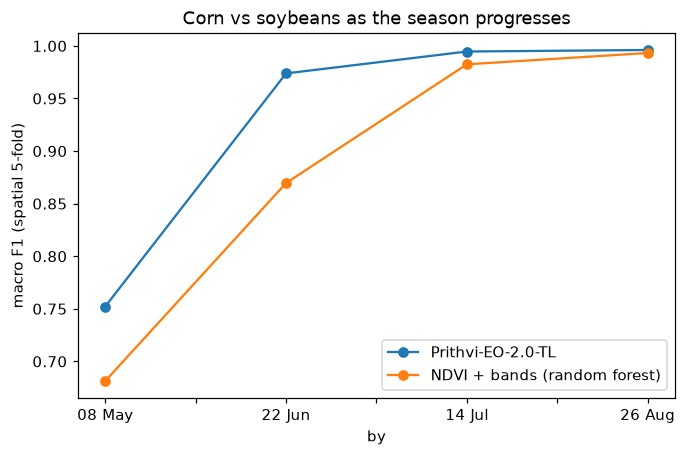

,Prithvi-EO-2.0-TL,NDVI + bands (random forest)
by,,
08 May,0.752,0.681
22 Jun,0.974,0.870
14 Jul,0.995,0.983
26 Aug,0.996,0.993


In [8]:
rows = []  # early-season results
for T in [1, 2, 3, 4]:  # dates available by May, June, July, August
    sub = series.isel(time=slice(0, T))  # the first T dates
    enc = fm.load_model("prithvi-eo-2.0-300m-tl", device=DEVICE, num_frames=T)  # Prithvi-TL for T frames
    E = cells(enc.embed_raster(sub, dense=True, norm="model", batch_size=4, metadata=True))  # embeddings
    del enc; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
    rf = RandomForestClassifier(300, n_jobs=-1, random_state=SEED)  # baseline
    feats = np.c_[nd_cell[:, :T], bm[:, :T].reshape(len(bm), -1)]  # NDVI + bands of those dates
    when = pd.Timestamp(DATES[T - 1]).strftime("%d %b")  # last date used
    rows.append({"by": when, "Prithvi-EO-2.0-TL": fm.linear_probe(E[ok], y[ok], groups=group[ok])["mean"]["f1_macro"],
                 "NDVI + bands (random forest)": cross_val_score(rf, feats[ok], y[ok], groups=group[ok], cv=GroupKFold(5),
                                                                 scoring="f1_macro").mean()})  # both scores
early = pd.DataFrame(rows).set_index("by")  # by date
ax = early.plot(marker="o", figsize=(7, 4.3)); ax.set_ylabel("macro F1 (spatial 5-fold)")  # curve
ax.set_title("Corn vs soybeans as the season progresses"); plt.show()  # draw
early.round(3)

Early in the season the foundation model earns its place. With only the 8 May image, when both crops
are bare soil or seedlings, Prithvi-TL reaches a macro F1 of about 0.75 against 0.68 for the random
forest. By 22 June it is at about 0.97, while the random forest needs the July image to reach that
level. A map of this quality is available about three weeks earlier. From mid-July on both methods
agree. Where pretrained features help is exactly where labels and spectral contrast are scarce: here,
in the weeks after planting.

## Presto and Galileo

Two time series models in the catalog run through their authors' code rather than `fm.load_model`:

In [9]:
pd.concat([fm.list_models("timeseries"), fm.list_models("multimodal").loc[["galileo"]]])[
    ["provider", "year", "params", "embed_dim", "weights", "use_cases"]]  # Presto, Galileo and the embedding products

,provider,year,params,embed_dim,weights,use_cases
name,,,,,,
alphaearth,Google DeepMind,2025,n/a (precomputed),64.0,Earth Engine GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL,covariates for spatial ML; digital soil mappin...
presto,NASA Harvest,2023,0.4M,128.0,github.com/nasaharvest/presto,crop type mapping; cheap CPU inference
tessera,University of Cambridge,2025,n/a,128.0,github.com/ucam-eo/tessera,precomputed 10 m embeddings; crop and habitat ...
galileo,NASA Harvest / Ai2 et al.,2025,nano to base,768.0,nasaharvest/galileo,crop mapping; time series; small-object detection


**Presto** (Tseng et al. 2023) is a 0.4 million parameter transformer for single pixels. It reads a
year of monthly Sentinel-1, Sentinel-2, ERA5 climate, SRTM elevation and dynamic world values, each
optional, and returns a 128-value embedding. It is small enough to embed millions of pixels on a CPU,
which suits national crop maps. **Galileo** (Tseng et al. 2025) extends the idea to space and time
with many inputs (Sentinel-1 and 2, ERA5, TerraClimate, elevation, night lights) and both global and
local masked objectives, in sizes from nano to base.

Both are installed from their repositories (`pip install` from `github.com/nasaharvest/presto` and
`github.com/nasaharvest/galileo`) and expect monthly composites per pixel with their own band order
and normalization. The GeoLattice workflow is the same as above: build the monthly series with
`geolattice.rsense.timeseries`, embed it with the authors' model, and evaluate the embeddings with
`fm.linear_probe` and spatial groups. Their catalog entries record the weights and references:

In [10]:
pd.DataFrame({n: fm.model_info(n) for n in ["presto", "galileo", "tessera"]}).loc[["inputs", "weights", "reference", "notes"]]  # details

,presto,galileo,tessera
inputs,"monthly S1, S2, ERA5, SRTM, NDVI per pixel","S1, S2, ERA5, TerraClimate, DEM, VIIRS, ... as...",annual S1 + S2 pixel time series
weights,github.com/nasaharvest/presto,nasaharvest/galileo,github.com/ucam-eo/tessera
reference,"Tseng et al. 2023, arXiv:2304.14065","Tseng et al. 2025, arXiv:2502.09356","Feng et al. 2025, arXiv:2506.20380"
notes,,,


## Summary and exercises

### Summary

- Time enters foundation models as 3-D patches, date tokens, location tokens, temporal attention or
  per-pixel sequences; `fm.chip_raster` and `embed_raster` accept a `(time, band, y, x)` series.
- Prithvi-EO-2.0 reads one to four frames; the TL variant also takes dates and coordinates, filled by
  `embed_raster(metadata=True)` from `fm.chip_metadata`.
- AnySat takes each modality with its own dates and returns tile or patch embeddings.
- NDVI phenology with a random forest is a strong baseline for corn and soybeans; foundation model
  embeddings have to be compared with it under spatial cross-validation.
- Accuracy grows as the season progresses; the early-season curve shows when a map becomes usable.
- Presto and Galileo are pixel and space-time models run through their authors' code, then evaluated
  with the same probes.

### Exercises

1. Replace the four monthly dates with the clearest date of each two-week period and rerun Prithvi-TL
   with four frames. Does the choice of dates matter more than the model?
2. Give the TL model a wrong year (2015) in its temporal coordinates. How much does the probe change?
3. Run AnySat with `output="patch"` and average its patches per cell, as done for Prithvi.
4. Add the Sentinel-1 series to AnySat's input dictionary (`"s1"` with its own dates). Does radar help
   in May and June?
5. Build monthly composites for a whole year with `geolattice.rsense.timeseries` and plan how you would feed
   them to Presto.

### References

- Astruc, G. et al. (2025). AnySat: one Earth observation model for many resolutions, scales, and modalities. CVPR.
- Garnot, V. S. F. and Landrieu, L. (2020). Lightweight temporal self-attention for classifying satellite images time series. AALTD.
- Szwarcman, D. et al. (2024). Prithvi-EO-2.0. arXiv:2412.02732.
- Tseng, G. et al. (2023). Lightweight, pre-trained transformers for remote sensing timeseries (Presto). arXiv:2304.14065.
- Tseng, G. et al. (2025). Galileo: learning global and local features in pretrained remote sensing models. arXiv:2502.09356.